In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
df = pd.read_csv("cleaned_data.csv")
print(df.shape)
df.head()


(891, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35,0,0,373450,8.0500,S


In [2]:
# Key statistics
df.describe()



,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.356902,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.017814,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [3]:
# Create two helpful new columns
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['AgeGroup'] = pd.cut(df['Age'], bins=[0, 12, 18, 35, 60, 100],
                        labels=['Child', 'Teen', 'Young Adult', 'Adult', 'Senior'])

print("Overall survival rate:", round(df['Survived'].mean() * 100, 1), "%")
print("\nSurvival by Sex:\n", (df.groupby('Sex')['Survived'].mean() * 100).round(1))
print("\nSurvival by Class:\n", (df.groupby('Pclass')['Survived'].mean() * 100).round(1))
print("\nSurvival by Port:\n", (df.groupby('Embarked')['Survived'].mean() * 100).round(1))
print("\nSurvival by Age Group:\n", (df.groupby('AgeGroup', observed=True)['Survived'].mean() * 100).round(1))
print("\nSurvival by Family Size:\n", (df.groupby('FamilySize')['Survived'].mean() * 100).round(1))
print("\nMedian fare by Class:\n", df.groupby('Pclass')['Fare'].median())

Overall survival rate: 38.4 %

Survival by Sex:
 Sex
female    74.2
male      18.9
Name: Survived, dtype: float64

Survival by Class:
 Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64

Survival by Port:
 Embarked
C    55.4
Q    39.0
S    33.9
Name: Survived, dtype: float64

Survival by Age Group:
 AgeGroup
Child          57.4
Teen           42.9
Young Adult    35.3
Adult          40.0
Senior         22.7
Name: Survived, dtype: float64

Survival by Family Size:
 FamilySize
1     30.4
2     55.3
3     57.8
4     72.4
5     20.0
6     13.6
7     33.3
8      0.0
11     0.0
Name: Survived, dtype: float64

Median fare by Class:
 Pclass
1    60.2875
2    14.2500
3     8.0500
Name: Fare, dtype: float64


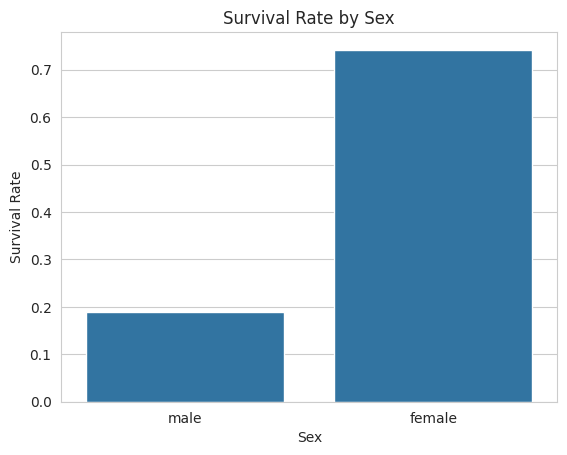

In [11]:
# Chart 1: Survival by Sex
sns.barplot(data=df, x='Sex', y='Survived', errorbar=None)
plt.title("Survival Rate by Sex")
plt.ylabel("Survival Rate")
plt.savefig("1_survival_by_sex.png", dpi=150, bbox_inches='tight')
plt.show()

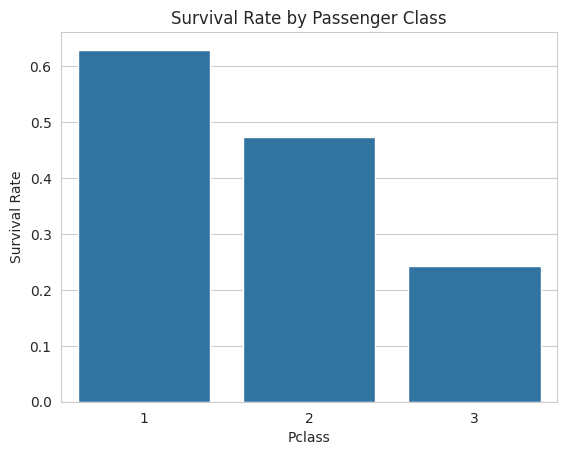

In [12]:
# Chart 2: Survival by Class
sns.barplot(data=df, x='Pclass', y='Survived', errorbar=None)
plt.title("Survival Rate by Passenger Class")
plt.ylabel("Survival Rate")
plt.savefig("2_survival_by_class.png", dpi=150, bbox_inches='tight')
plt.show()

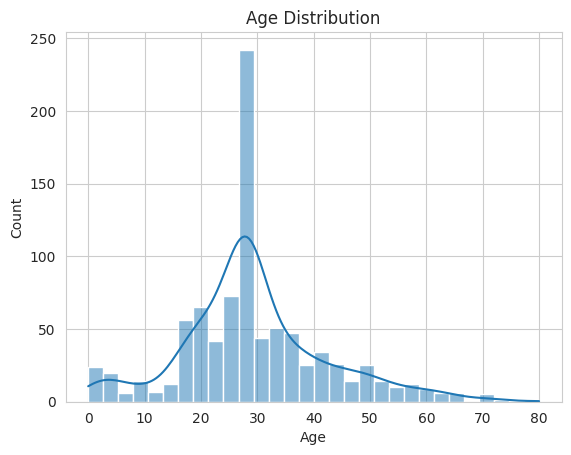

In [13]:
# Chart 3: Age distribution
sns.histplot(df['Age'], bins=30, kde=True)
plt.title("Age Distribution")
plt.savefig("3_age_distribution.png", dpi=150, bbox_inches='tight')
plt.show()

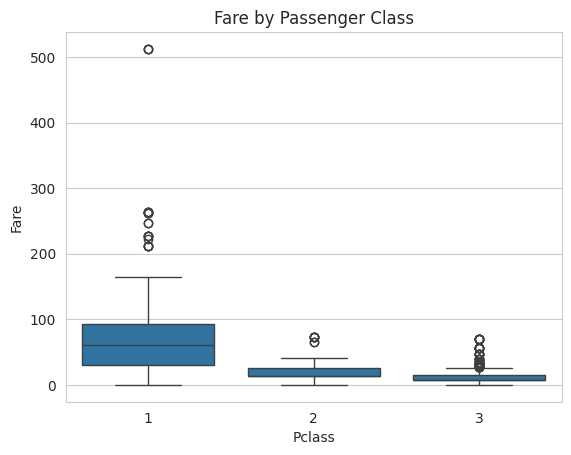

In [14]:
# Chart 4: Fare by Class (shows outliers)
sns.boxplot(data=df, x='Pclass', y='Fare')
plt.title("Fare by Passenger Class")
plt.savefig("4_fare_by_class.png", dpi=150, bbox_inches='tight')
plt.show()

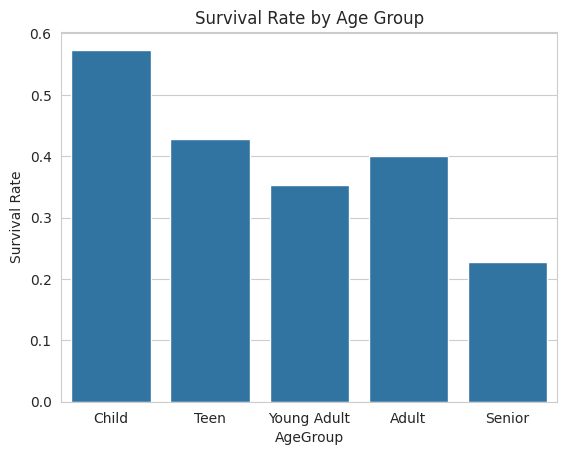

In [15]:
# Chart 5: Survival by Age Group
sns.barplot(data=df, x='AgeGroup', y='Survived', errorbar=None)
plt.title("Survival Rate by Age Group")
plt.ylabel("Survival Rate")
plt.savefig("5_survival_by_age_group.png", dpi=150, bbox_inches='tight')
plt.show()

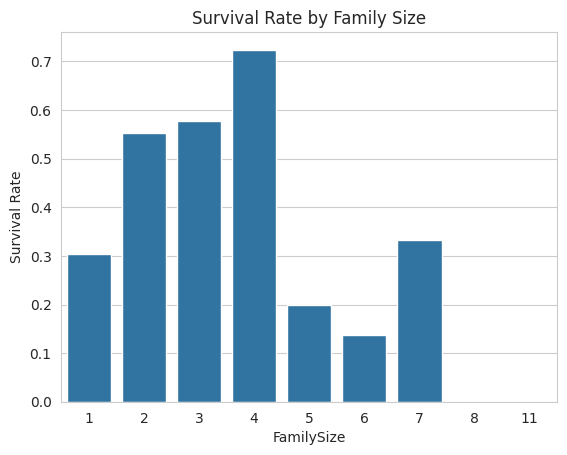

In [16]:
# Chart 6: Survival by Family Size
sns.barplot(data=df, x='FamilySize', y='Survived', errorbar=None)
plt.title("Survival Rate by Family Size")
plt.ylabel("Survival Rate")
plt.savefig("6_survival_by_family_size.png", dpi=150, bbox_inches='tight')
plt.show()

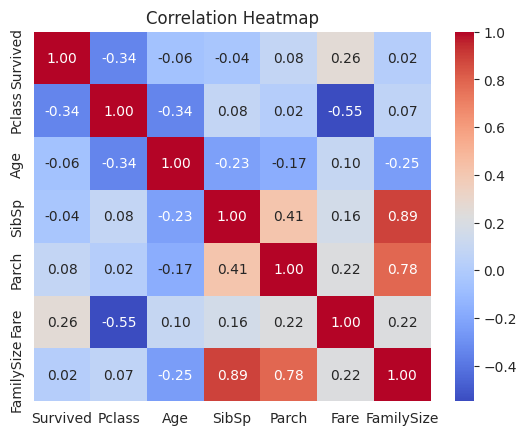

In [17]:
# Chart 7: Correlation heatmap
sns.heatmap(df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize']].corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.savefig("7_correlation_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()

In [18]:
print(pd.crosstab(df['Embarked'], df['Pclass'], normalize='index').round(2) * 100)

Pclass       1     2     3
Embarked                  
C         51.0  10.0  39.0
Q          3.0   4.0  94.0
S         20.0  25.0  55.0


## Key Insights

1. **Sex was the strongest factor:** 74.2% of women survived compared to 18.9% of men. The overall survival rate was 38.4%.

2. **Passenger class mattered:** survival fell from 63.0% in 1st class to 47.3% in 2nd class and 24.2% in 3rd class.

3. **Fare reflects class:** the median fare was 60.29 in 1st class, 14.25 in 2nd class and 8.05 in 3rd class, so wealthier passengers paid far more and also survived more often.

4. **Children had the best chances:** the Child group (0-12) had a 57.4% survival rate, compared to 35.3% for Young Adults and 22.7% for Seniors.

5. **Port of embarkation showed a difference:** passengers from Cherbourg (C) survived at 55.4%, compared to 39.0% from Queenstown (Q) and 33.9% from Southampton (S). This is likely linked to class, since more 1st class passengers boarded at Cherbourg.

6. **Family size had a sweet spot:** passengers travelling with 2-4 family members (survival 55.3% to 72.4%) did better than those travelling alone (30.4%). Very large families did much worse (13.6% for size 6, and 0% for sizes 8 and 11).

7. **Anomaly:** the Age chart has a tall spike at 28 because missing ages were filled with the median in Task 1. Results for Age should be read with this in mind.